<a href="https://colab.research.google.com/github/sso-eun/YOLO-Urban-Drainage-Monitoring/blob/main/Urban_Drainage_Monitoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 공통

# ====================================
# YOLO Flood Project
# 공통 라이브러리
# ====================================

import os
import random
import shutil
import yaml
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter, defaultdict

from ultralytics import YOLO


In [ ]:

import torch

print("PyTorch 버전:", torch.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU 이름:", torch.cuda.get_device_name(0))
    print("GPU 메모리:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
          "GB")


PyTorch 버전: 2.14.1+cu130
GPU 사용 가능: True
GPU 이름: Tesla T4
GPU 메모리: 14.6 GB


In [ ]:
!pip install -U ultralytics

In [ ]:
from ultralytics import YOLO
import ultralytics

print("Ultralytics 버전:", ultralytics.__version__)

Ultralytics 버전: 8.4.216


In [ ]:

from google.colab import drive

# Google Drive 연결
drive.mount('/content/drive')

# 프로젝트 폴더 생성
project_dir = '/content/drive/MyDrive/YOLO_Flood_Project'
os.makedirs(project_dir, exist_ok=True)

print("프로젝트 폴더:", project_dir)
print("폴더 생성 완료!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
프로젝트 폴더: /content/drive/MyDrive/YOLO_Flood_Project
폴더 생성 완료!


In [ ]:
!pip install -q roboflow

In [ ]:

from roboflow import Roboflow

rf = Roboflow(api_key="IOUR7Gbg3s5VrbVDNOVl")
project = rf.workspace("siyin").project("drain-2048")
version = project.version(17)

dataset = version.download("yolov8")

print("다운로드 위치:", dataset.location)


loading Roboflow workspace...
loading Roboflow project...
다운로드 위치: /content/drain-2048-17


In [ ]:
print("데이터셋 경로:", dataset.location)

with open(os.path.join(dataset.location, "data.yaml")) as f:
    data = yaml.safe_load(f)

print("클래스 정보:", data["names"])

for split in ["train", "valid", "test"]:
    folder = os.path.join(dataset.location, split, "images")
    if os.path.exists(folder):
        print(split, "이미지 수:", len(os.listdir(folder)))


데이터셋 경로: /content/drain-2048-17
클래스 정보: ['drain']
train 이미지 수: 184
valid 이미지 수: 102


In [ ]:

# 배수구 라벨링 이미지 몇장인지 확인

dataset_path = Path(dataset.location)

total_images = 0
labeled_images = 0
total_objects = 0

for split in ["train", "valid", "test"]:
    images_dir = dataset_path / split / "images"
    labels_dir = dataset_path / split / "labels"

    if not images_dir.exists():
        continue

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    split_labeled = 0
    split_objects = 0

    for img in images:
        label_file = labels_dir / (img.stem + ".txt")

        if not label_file.exists():
            continue

        lines = [
            line.strip()
            for line in label_file.read_text().splitlines()
            if line.strip()
        ]

        if lines:
            split_labeled += 1
            split_objects += len(lines)

    total_images += len(images)
    labeled_images += split_labeled
    total_objects += split_objects

    print(f"{split}:")
    print(f"  전체 이미지: {len(images)}")
    print(f"  라벨 있는 이미지: {split_labeled}")
    print(f"  객체 수: {split_objects}")

print("\n=== 전체 결과 ===")
print("전체 이미지:", total_images)
print("라벨 있는 이미지:", labeled_images)
print("전체 객체 수:", total_objects)


train:
  전체 이미지: 184
  라벨 있는 이미지: 184
  객체 수: 215
valid:
  전체 이미지: 102
  라벨 있는 이미지: 102
  객체 수: 115

=== 전체 결과 ===
전체 이미지: 286
라벨 있는 이미지: 286
전체 객체 수: 330


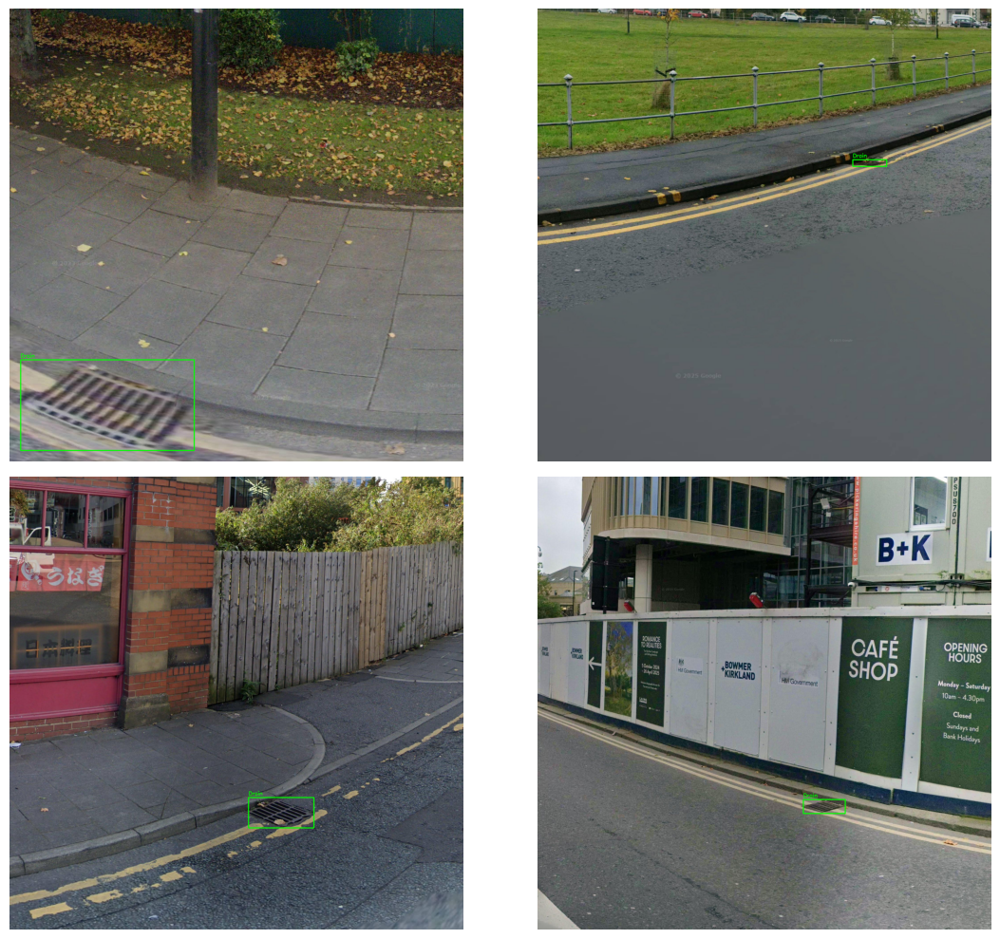

In [ ]:

images_dir = Path(dataset.location) / "train" / "images"
labels_dir = Path(dataset.location) / "train" / "labels"

images = [
    p for p in images_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

# 무작위 이미지 4장 선택
random.seed(42)
samples = random.sample(images, 4)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, image_path in zip(axes.flat, samples):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]
    label_path = labels_dir / (image_path.stem + ".txt")

    for line in label_path.read_text().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())

        x1 = int((xc - bw / 2) * width)
        y1 = int((yc - bh / 2) * height)
        x2 = int((xc + bw / 2) * width)
        y2 = int((yc + bh / 2) * height)

        cv2.rectangle(image, (x1, y1), (x2, y2),
                      (0, 255, 0), 3)

        cv2.putText(image, "Drain", (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8,
                    (0, 255, 0), 2)

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Drain dataset backup

In [ ]:
source = Path(dataset.location)

backup_dir = Path(
    "/content/drive/MyDrive/YOLO_Flood_Project/datasets/drain"
)

backup_dir.parent.mkdir(parents=True, exist_ok=True)

shutil.copytree(source, backup_dir, dirs_exist_ok=True)

print("백업 완료!")
print("저장 경로:", backup_dir)


백업 완료!
저장 경로: /content/drive/MyDrive/YOLO_Flood_Project/datasets/drain


In [ ]:
# puddle

rf = Roboflow(api_key="IOUR7Gbg3s5VrbVDNOVl")
project = rf.workspace("hayato-hagiwara").project("puddle-sikk1-5pd0c")
version = project.version(1)
# dataset = version.download("yolov8")
puddle_dataset = version.download("yolov8")
print("Puddle 데이터셋:", puddle_dataset.location)


loading Roboflow workspace...
loading Roboflow project...
Puddle 데이터셋: /content/puddle-1


In [ ]:
# puddle 클래스 확인, 라벨링 이미지 장 수, 학습, 검증 데이터 분리여부

puddle_path = Path(puddle_dataset.location)

# 클래스 구성 확인
with open(puddle_path / "data.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("클래스 정보:", config["names"])

total_images = 0
total_labeled = 0
total_objects = 0

for split in ["train", "valid", "test"]:
    images_dir = puddle_path / split / "images"
    labels_dir = puddle_path / split / "labels"

    if not images_dir.exists():
        continue

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    labeled = 0
    objects = 0

    for image in images:
        label_file = labels_dir / (image.stem + ".txt")

        if not label_file.exists():
            continue

        lines = [
            line.strip()
            for line in label_file.read_text().splitlines()
            if line.strip()
        ]

        if lines:
            labeled += 1
            objects += len(lines)

    total_images += len(images)
    total_labeled += labeled
    total_objects += objects

    print(f"\n{split}:")
    print(" 전체 이미지:", len(images))
    print(" 라벨 있는 이미지:", labeled)
    print(" 객체 수:", objects)

print("\n=== 전체 결과 ===")
print("전체 이미지:", total_images)
print("라벨 있는 이미지:", total_labeled)
print("전체 객체 수:", total_objects)


클래스 정보: ['puddle']

train:
 전체 이미지: 869
 라벨 있는 이미지: 864
 객체 수: 1200

valid:
 전체 이미지: 330
 라벨 있는 이미지: 329
 객체 수: 422

test:
 전체 이미지: 300
 라벨 있는 이미지: 298
 객체 수: 400

=== 전체 결과 ===
전체 이미지: 1499
라벨 있는 이미지: 1491
전체 객체 수: 2022


In [ ]:

# 라벨형식 확인..
# 물웅덩이는 점을 연결해서 외곽을 표시하고, 바운딩박스처리는 안되어 이 ㅆ음

labels_dir = Path(puddle_dataset.location) / "train" / "labels"

# 라벨 파일 하나 확인
for label_file in labels_dir.glob("*.txt"):
    lines = [
        line.strip()
        for line in label_file.read_text().splitlines()
        if line.strip()
    ]

    if lines:
        print("파일명:", label_file.name)
        print("첫 번째 라벨:", lines[0])
        print("숫자 개수:", len(lines[0].split()))
        break


파일명: image106_jpeg_jpg.rf.6b4341a3ff492df821f6c04839644af0.txt
첫 번째 라벨: 0 0.17229557104644244 0.622444907333815 0.20810575418875915 0.635159765755272 0.23582979821685507 0.6420952272561105 0.2623986921046775 0.652498353365905 0.28088135874597264 0.657122082555081 0.30513986422094164 0.6501865769599341 0.35134657489033283 0.6316920570520071 0.36751894125108087 0.6293802365517277 0.3871567580326496 0.6224449073338149 0.4218117910346928 0.5935472613160931 0.43567385711489415 0.5785204060171226 0.441449695948568 0.566961347610034 0.4229669411749663 0.5530904687026659 0.4298980182812201 0.532284172388768 0.4148808020607454 0.5184132934813998 0.3825360693392492 0.5149455847781351 0.36751894125108087 0.5056983468713258 0.33979489722298495 0.513789652480841 0.32477768100251037 0.5218810021846648 0.29012264800046705 0.5288164636855031 0.2797262086056992 0.5380637015923123 0.24391593733107597 0.5449991189988421 0.20695060404848578 0.5449991189988421 0.17576110959956937 0.570429056313299 0.149192

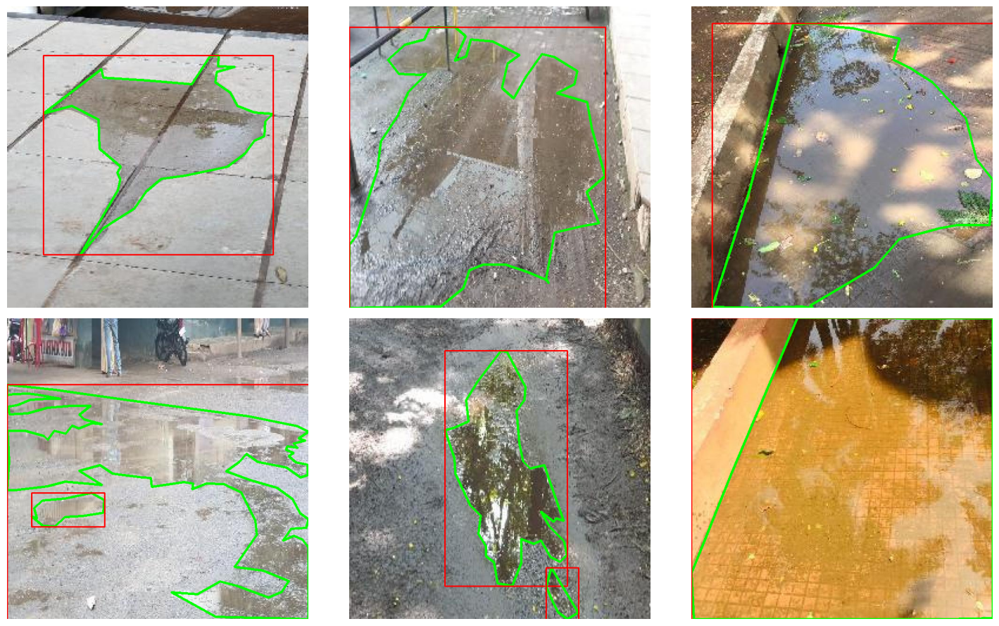

In [ ]:
# 물웅덩이는 세그멘테이션 라벨을 시각화해야함. (점으로 이어져있기만해서)


images_dir = Path(puddle_dataset.location) / "train" / "images"
labels_dir = Path(puddle_dataset.location) / "train" / "labels"

images = [
    p for p in images_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

random.seed(42)
samples = random.sample(images, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, image_path in zip(axes.flat, samples):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]
    label_path = labels_dir / (image_path.stem + ".txt")

    if label_path.exists():
        for line in label_path.read_text().splitlines():

            values = list(map(float, line.split()))
            coords = np.array(values[1:]).reshape(-1, 2)

            # 정규화 좌표를 실제 픽셀 좌표로 변환
            points = np.column_stack((
                coords[:, 0] * w,
                coords[:, 1] * h
            )).astype(np.int32)

            # 물웅덩이 외곽선
            cv2.polylines(
                image, [points], True,
                (0, 255, 0), 3
            )

            # 세그멘테이션을 둘러싸는 바운딩 박스
            x, y, bw, bh = cv2.boundingRect(points)

            cv2.rectangle(
                image, (x, y), (x + bw, y + bh),
                (255, 0, 0), 2
            )

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# 일단 웅덩이도 백업

source = Path(puddle_dataset.location)

backup_dir = Path(
    "/content/drive/MyDrive/YOLO_Flood_Project/datasets/puddle"
)

backup_dir.parent.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    source,
    backup_dir,
    dirs_exist_ok=True
)

print("Puddle 데이터셋 백업 완료!")
print("저장 경로:", backup_dir)


Puddle 데이터셋 백업 완료!
저장 경로: /content/drive/MyDrive/YOLO_Flood_Project/datasets/puddle


In [ ]:
# Debris(낙엽) 데이터셋

rf = Roboflow(api_key="IOUR7Gbg3s5VrbVDNOVl")
project = rf.workspace("wqwdas").project("drain-test")
version = project.version(2)
debris_dataset = version.download("yolov8")

print("Debris 데이터셋:", debris_dataset.location)


loading Roboflow workspace...
loading Roboflow project...
Debris 데이터셋: /content/drain-test-2


In [ ]:
# Debris 데이터셋 클래스 분석

debris_path = Path(debris_dataset.location)

# 데이터셋 클래스 확인
with open(debris_path / "data.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, dict):
    class_names = {int(k): v for k, v in names.items()}
else:
    class_names = dict(enumerate(names))

print("=== 클래스 목록 ===")
for class_id, name in class_names.items():
    print(f"{class_id}: {name}")

# 클래스별 이미지 수와 객체 수
image_counts = defaultdict(set)
object_counts = defaultdict(int)

print("\n=== 데이터 분할 ===")

for split in ["train", "valid", "test"]:
    images_dir = debris_path / split / "images"
    labels_dir = debris_path / split / "labels"

    if not images_dir.exists():
        continue

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    print(f"{split}: {len(images)}장")

    for img in images:
        label_file = labels_dir / (img.stem + ".txt")

        if not label_file.exists():
            continue

        for line in label_file.read_text().splitlines():
            values = line.split()

            if not values:
                continue

            class_id = int(values[0])

            image_counts[class_id].add(
                (split, img.name)
            )
            object_counts[class_id] += 1

print("\n=== 클래스별 분석 결과 ===")

for class_id, name in class_names.items():
    print(f"\n{name} (Class {class_id})")
    print("  라벨 있는 이미지:",
          len(image_counts[class_id]))
    print("  객체 수:",
          object_counts[class_id])


=== 클래스 목록 ===
0: drainage
1: leaf
2: rock
3: silt
4: trash

=== 데이터 분할 ===
train: 2259장
valid: 94장
test: 94장

=== 클래스별 분석 결과 ===

drainage (Class 0)
  라벨 있는 이미지: 1221
  객체 수: 1253

leaf (Class 1)
  라벨 있는 이미지: 476
  객체 수: 1336

rock (Class 2)
  라벨 있는 이미지: 156
  객체 수: 284

silt (Class 3)
  라벨 있는 이미지: 235
  객체 수: 315

trash (Class 4)
  라벨 있는 이미지: 537
  객체 수: 874


대상 이미지: 818


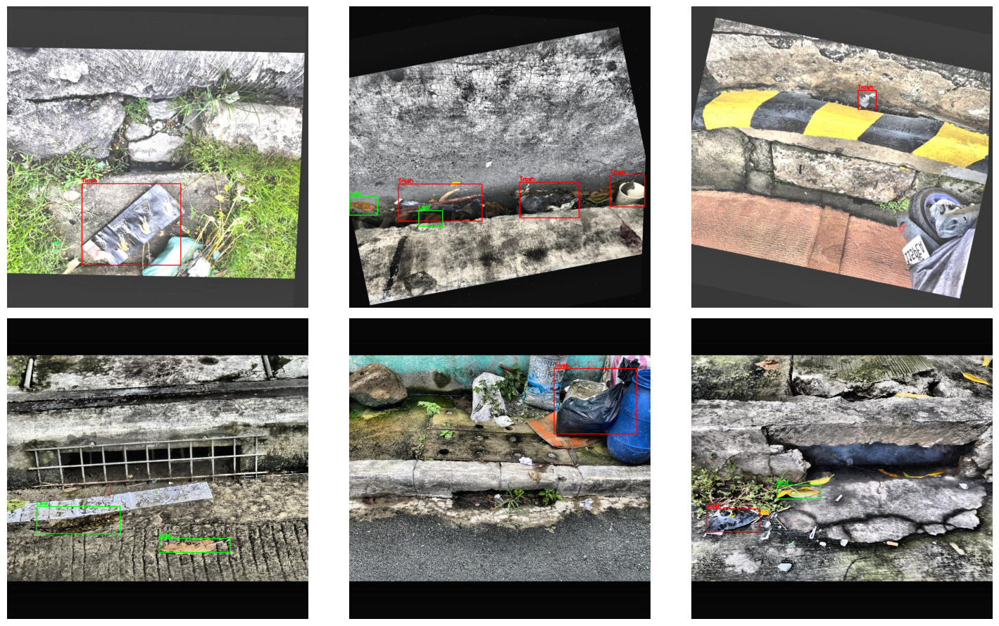

In [ ]:
# 낙엽, 쓰레기 라벨 시각화해서 확인
# 낙엽은 초록색, 쓰레기는 빨간색

root = Path(debris_dataset.location)
images_dir = root / "train" / "images"
labels_dir = root / "train" / "labels"

# leaf(1), trash(4)가 포함된 이미지 찾기
candidates = []

for img in images_dir.iterdir():
    if img.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue

    label_path = labels_dir / (img.stem + ".txt")

    if not label_path.exists():
        continue

    classes = {
        int(float(line.split()[0]))
        for line in label_path.read_text().splitlines()
        if line.strip()
    }

    if 1 in classes or 4 in classes:
        candidates.append(img)

print("대상 이미지:", len(candidates))

random.seed(42)
samples = random.sample(candidates, min(6, len(candidates)))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, image_path in zip(axes.flat, samples):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]
    label_path = labels_dir / (image_path.stem + ".txt")

    for line in label_path.read_text().splitlines():
        values = list(map(float, line.split()))
        cls = int(values[0])

        if cls not in [1, 4]:
            continue

        # 일반 YOLO Detection 라벨
        if len(values) == 5:
            _, xc, yc, bw, bh = values

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

        # Segmentation 라벨도 처리
        elif len(values) >= 7 and (len(values)-1) % 2 == 0:
            coords = np.array(values[1:]).reshape(-1, 2)
            x1 = int(coords[:, 0].min() * w)
            y1 = int(coords[:, 1].min() * h)
            x2 = int(coords[:, 0].max() * w)
            y2 = int(coords[:, 1].max() * h)
        else:
            continue

        color = (0, 255, 0) if cls == 1 else (255, 0, 0)
        name = "Leaf" if cls == 1 else "Trash"

        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        cv2.putText(
            image, name, (x1, max(20, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2
        )

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
source = Path(debris_dataset.location)

backup_dir = Path(
    "/content/drive/MyDrive/YOLO_Flood_Project/datasets/debris_original"
)

backup_dir.parent.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    source,
    backup_dir,
    dirs_exist_ok=True
)

print("Debris 원본 데이터셋 백업 완료!")
print("저장 경로:", backup_dir)


Debris 원본 데이터셋 백업 완료!
저장 경로: /content/drive/MyDrive/YOLO_Flood_Project/datasets/debris_original


### 데이터셋 통합
#### 목표

최종 ID	클래스	원본 <br>
0	Drain	drain + drainage(검토 후 결정) <br>
1	Puddle	puddle <br>
2	Debris	leaf + trash <br>


In [ ]:

datasets = {
    "Drain": Path("/content/drive/MyDrive/YOLO_Flood_Project/datasets/drain"),
    "Puddle": Path("/content/drive/MyDrive/YOLO_Flood_Project/datasets/puddle"),
    "Debris": Path("/content/drive/MyDrive/YOLO_Flood_Project/datasets/debris_original")
}

for name, root in datasets.items():
    formats = Counter()

    for split in ["train", "valid", "test"]:
        labels_dir = root / split / "labels"

        if not labels_dir.exists():
            continue

        for label_file in labels_dir.glob("*.txt"):
            for line in label_file.read_text().splitlines():
                values = line.split()

                if not values:
                    continue

                if len(values) == 5:
                    formats["Detection"] += 1
                elif len(values) >= 7 and len(values) % 2 == 1:
                    formats["Segmentation"] += 1
                else:
                    formats["기타"] += 1

    print(f"\n=== {name} ===")
    print(dict(formats))



=== Drain ===
{'Detection': 330}

=== Puddle ===
{'Segmentation': 2021, 'Detection': 1}

=== Debris ===
{'Detection': 3023, 'Segmentation': 1039}


Drainage 포함 이미지: 1130


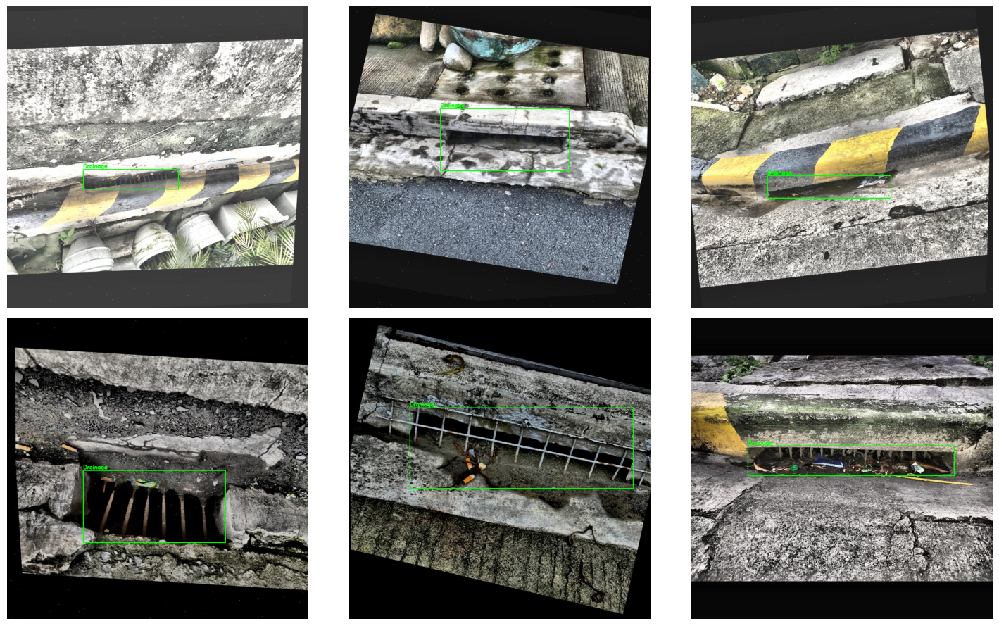

In [ ]:

# Drainage 객체가 뭔지 확인

root = Path(
    "/content/drive/MyDrive/YOLO_Flood_Project/datasets/debris_original"
)

images_dir = root / "train" / "images"
labels_dir = root / "train" / "labels"

candidates = []

for img in images_dir.iterdir():
    if img.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue

    label_path = labels_dir / (img.stem + ".txt")

    if not label_path.exists():
        continue

    for line in label_path.read_text().splitlines():
        values = line.split()

        if values and int(float(values[0])) == 0:
            candidates.append(img)
            break

print("Drainage 포함 이미지:", len(candidates))

random.seed(24)
samples = random.sample(candidates, min(6, len(candidates)))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, image_path in zip(axes.flat, samples):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]
    label_path = labels_dir / (image_path.stem + ".txt")

    for line in label_path.read_text().splitlines():
        values = list(map(float, line.split()))

        if int(values[0]) != 0:
            continue

        if len(values) == 5:
            _, xc, yc, bw, bh = values
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

        elif len(values) >= 7 and len(values) % 2 == 1:
            coords = np.array(values[1:]).reshape(-1, 2)

            x1 = int(coords[:, 0].min() * w)
            y1 = int(coords[:, 1].min() * h)
            x2 = int(coords[:, 0].max() * w)
            y2 = int(coords[:, 1].max() * h)

        else:
            continue

        cv2.rectangle(
            image, (x1, y1), (x2, y2),
            (0, 255, 0), 2
        )

        cv2.putText(
            image, "Drainage",
            (x1, max(20, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6, (0, 255, 0), 2
        )

    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()
plt.show()


#### 데이터 통합 준비(2) <br>
0 : Drain  // 원본 : drain, drainage <br>
1 : Puddle // puddle  <br>
2 : Debris  // leaf, trash <br>

In [ ]:

# ==========================================
# 10-1. 데이터셋 통합 준비
# ==========================================

from pathlib import Path
import yaml

base_dir = Path(
    "/content/drive/MyDrive/YOLO_Flood_Project"
)

sources = {
    "drain": base_dir / "datasets/drain",
    "puddle": base_dir / "datasets/puddle",
    "debris": base_dir / "datasets/debris_original"
}

# 원본 데이터셋 확인
for name, path in sources.items():
    print(f"\n=== {name.upper()} ===")

    print("폴더 존재:", path.exists())

    yaml_path = path / "data.yaml"

    if yaml_path.exists():
        with open(yaml_path, encoding="utf-8") as f:
            config = yaml.safe_load(f)

        print("원본 클래스:", config["names"])
    else:
        print("data.yaml 없음!")

# 최종 데이터셋 폴더 생성
merged_dir = base_dir / "merged_dataset"

for split in ["train", "valid", "test"]:
    (merged_dir / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (merged_dir / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

print("\n최종 통합 폴더 생성 완료!")
print("경로:", merged_dir)



=== DRAIN ===
폴더 존재: True
원본 클래스: ['drain']

=== PUDDLE ===
폴더 존재: True
원본 클래스: ['puddle']

=== DEBRIS ===
폴더 존재: True
원본 클래스: ['drainage', 'leaf', 'rock', 'silt', 'trash']

최종 통합 폴더 생성 완료!
경로: /content/drive/MyDrive/YOLO_Flood_Project/merged_dataset


In [ ]:
# 실제 통합에 사용할 수 있는 이미지 수 계산


# ==========================================
# 10-2. Debris 데이터 선별
# ==========================================

debris_root = sources["debris"]

total = 0
usable = 0
excluded = 0

usable_leaf = 0
usable_trash = 0

for split in ["train", "valid", "test"]:
    images_dir = debris_root / split / "images"
    labels_dir = debris_root / split / "labels"

    if not images_dir.exists():
        continue

    for img in images_dir.iterdir():

        if img.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        total += 1

        label_path = labels_dir / (img.stem + ".txt")

        if not label_path.exists():
            continue

        classes = set()

        for line in label_path.read_text().splitlines():
            values = line.split()

            if values:
                classes.add(int(float(values[0])))

        # rock 또는 silt 포함 이미지는 제외 후보
        if 2 in classes or 3 in classes:
            excluded += 1
            continue

        # Drain 또는 Debris 관련 객체가 있는 이미지
        if classes & {0, 1, 4}:
            usable += 1

            if 1 in classes:
                usable_leaf += 1

            if 4 in classes:
                usable_trash += 1

print("=== Debris 데이터 선별 결과 ===")
print("전체 이미지:", total)
print("제외 후보 이미지:", excluded)
print("사용 가능한 이미지:", usable)
print("낙엽 포함 이미지:", usable_leaf)
print("쓰레기 포함 이미지:", usable_trash)


=== Debris 데이터 선별 결과 ===
전체 이미지: 2447
제외 후보 이미지: 365
사용 가능한 이미지: 1104
낙엽 포함 이미지: 360
쓰레기 포함 이미지: 393


#### 실제 데이터셋 통합

In [ ]:

# ==========================================
# 10-3. YOLO 데이터셋 통합
# ==========================================

import shutil
from pathlib import Path
from collections import Counter

mapping = {
    "drain": {0: 0},
    "puddle": {0: 1},
    "debris": {0: 0, 1: 2, 4: 2}
}

stats = Counter()

def convert_label(line, new_class):
    values = list(map(float, line.split()))

    # Detection 라벨
    if len(values) == 5:
        _, xc, yc, bw, bh = values

    # Segmentation 라벨
    elif len(values) >= 7 and len(values) % 2 == 1:
        coords = np.array(values[1:]).reshape(-1, 2)

        x_min = coords[:, 0].min()
        y_min = coords[:, 1].min()
        x_max = coords[:, 0].max()
        y_max = coords[:, 1].max()

        xc = (x_min + x_max) / 2
        yc = (y_min + y_max) / 2
        bw = x_max - x_min
        bh = y_max - y_min
    else:
        return None

    return f"{new_class} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"

for source_name, source_root in sources.items():

    for split in ["train", "valid", "test"]:
        images_dir = source_root / split / "images"
        labels_dir = source_root / split / "labels"

        if not images_dir.exists():
            continue

        for img in images_dir.iterdir():
            if img.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
                continue

            label_file = labels_dir / (img.stem + ".txt")

            if not label_file.exists():
                continue

            lines = [
                line.strip()
                for line in label_file.read_text().splitlines()
                if line.strip()
            ]

            # Debris 원본: rock/silt 포함 이미지 제외
            if source_name == "debris":
                original_classes = {
                    int(float(line.split()[0]))
                    for line in lines
                }

                if 2 in original_classes or 3 in original_classes:
                    stats["excluded"] += 1
                    continue

            converted = []

            for line in lines:
                old_class = int(float(line.split()[0]))

                if old_class not in mapping[source_name]:
                    continue

                new_class = mapping[source_name][old_class]

                result = convert_label(line, new_class)

                if result is not None:
                    converted.append(result)
                    stats[f"class_{new_class}"] += 1

            # 대상 객체가 없는 이미지는 통합에서 제외
            if not converted:
                continue

            new_name = f"{source_name}_{img.stem}"

            target_img = merged_dir / split / "images" / (
                new_name + img.suffix.lower()
            )
            target_label = merged_dir / split / "labels" / (
                new_name + ".txt"
            )

            shutil.copy2(img, target_img)

            target_label.write_text(
                "\n".join(converted) + "\n",
                encoding="utf-8"
            )

            stats["images"] += 1

print("=== 통합 완료 ===")
print("총 이미지:", stats["images"])
print("Drain 객체:", stats["class_0"])
print("Puddle 객체:", stats["class_1"])
print("Debris 객체:", stats["class_2"])
print("제외된 Debris 이미지:", stats["excluded"])


=== 통합 완료 ===
총 이미지: 2881
Drain 객체: 1262
Puddle 객체: 2022
Debris 객체: 1740
제외된 Debris 이미지: 365


In [ ]:
# 데이터 무결성 검사.
# 오류 수, 클래스별 이미지 수, Detection 형식

# ==========================================
# 10-4. 통합 데이터셋 무결성 검사
# ==========================================

from collections import Counter
from pathlib import Path
import math

class_images = {0: set(), 1: set(), 2: set()}
class_objects = Counter()
errors = []
split_counts = {}

for split in ["train", "valid", "test"]:
    image_dir = merged_dir / split / "images"
    label_dir = merged_dir / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    labeled_count = 0

    for img in images:
        label_path = label_dir / (img.stem + ".txt")

        if not label_path.exists():
            errors.append(f"라벨 없음: {img.name}")
            continue

        labeled_count += 1

        for line_no, line in enumerate(
            label_path.read_text().splitlines(), 1
        ):
            if not line.strip():
                continue

            try:
                values = list(map(float, line.split()))

                if len(values) != 5:
                    raise ValueError("라벨 값이 5개가 아님")

                cls, xc, yc, bw, bh = values

                if not math.isfinite(cls) or not cls.is_integer():
                    raise ValueError("잘못된 클래스 ID")

                cls = int(cls)

                if cls not in [0, 1, 2]:
                    raise ValueError("허용되지 않은 클래스")

                if not all(math.isfinite(v) for v in [xc, yc, bw, bh]):
                    raise ValueError("유효하지 않은 좌표")

                if (
                    bw <= 0 or bh <= 0
                    or xc - bw / 2 < -1e-5
                    or yc - bh / 2 < -1e-5
                    or xc + bw / 2 > 1 + 1e-5
                    or yc + bh / 2 > 1 + 1e-5
                ):
                    raise ValueError("바운딩 박스 범위 오류")

                class_images[cls].add((split, img.name))
                class_objects[cls] += 1

            except (ValueError, IndexError) as e:
                errors.append(
                    f"{split}/{img.stem}.txt "
                    f"{line_no}번째 줄: {e}"
                )

    split_counts[split] = (len(images), labeled_count)

print("=== 데이터 분할 ===")
for split, (total, labeled) in split_counts.items():
    print(f"{split}: {total}장, 라벨 파일 {labeled}개")

print("\n=== 클래스별 결과 ===")
for cls, name in enumerate(["Drain", "Puddle", "Debris"]):
    print(
        f"{name}: "
        f"이미지 {len(class_images[cls])}장, "
        f"객체 {class_objects[cls]}개"
    )

print("\n=== 오류 검사 ===")
print("오류 수:", len(errors))
for error in errors[:10]:
    print(error)


=== 데이터 분할 ===
train: 2074장, 라벨 파일 2074개
valid: 472장, 라벨 파일 472개
test: 335장, 라벨 파일 335개

=== 클래스별 결과 ===
Drain: 이미지 1195장, 객체 1262개
Puddle: 이미지 1491장, 객체 2022개
Debris: 이미지 657장, 객체 1740개

=== 오류 검사 ===
오류 수: 0


In [ ]:
# 데이터누출 확인
# 같은 사진이 학습과 검증에 동시에 들어가면 안됀다

# ==========================================
# 10-5. 데이터 누출 검사
# ==========================================

import hashlib
from collections import defaultdict

hash_records = defaultdict(list)

for split in ["train", "valid", "test"]:
    image_dir = merged_dir / split / "images"

    for image_path in image_dir.iterdir():
        if image_path.suffix.lower() not in [
            ".jpg", ".jpeg", ".png"
        ]:
            continue

        # 파일 내용으로 SHA-256 해시 생성
        file_hash = hashlib.sha256(
            image_path.read_bytes()
        ).hexdigest()

        hash_records[file_hash].append(
            (split, image_path.name)
        )

# 서로 다른 분할에 존재하는 중복 이미지
leakages = []

for file_hash, records in hash_records.items():
    splits = {record[0] for record in records}

    if len(splits) > 1:
        leakages.append(records)

print("=== 데이터 누출 검사 ===")
print("검사한 고유 파일 해시:", len(hash_records))
print("분할 간 완전 중복 그룹:", len(leakages))

for records in leakages[:10]:
    print(records)


=== 데이터 누출 검사 ===
검사한 고유 파일 해시: 2880
분할 간 완전 중복 그룹: 1
[('train', 'puddle_image1r80_jpeg_jpg.rf.61011c012b48f4f17b5837e6c7eaf19c.jpg'), ('valid', 'puddle_image1r80_jpeg_jpg.rf.cf7cbf21f9db95a6d290fdbd5c0c2e97.jpg')]


In [ ]:

# ==========================================
# 10-6. 중복 이미지 제거
# ==========================================

from pathlib import Path

duplicate_name = (
    "puddle_image1r80_jpeg_jpg.rf."
    "cf7cbf21f9db95a6d290fdbd5c0c2e97.jpg"
)

image_path = merged_dir / "valid" / "images" / duplicate_name

label_path = (
    merged_dir / "valid" / "labels" /
    (Path(duplicate_name).stem + ".txt")
)

print("이미지 존재:", image_path.exists())
print("라벨 존재:", label_path.exists())

if image_path.exists() and label_path.exists():
    image_path.unlink()
    label_path.unlink()

    print("중복 이미지 및 라벨 제거 완료!")
else:
    print("파일을 찾지 못했습니다. 삭제하지 않았습니다.")


이미지 존재: True
라벨 존재: True
중복 이미지 및 라벨 제거 완료!


In [ ]:

# ==========================================
# 10-7. 원본 이미지 기준 분할 중복 검사
# ==========================================

from collections import defaultdict

original_groups = defaultdict(list)

for split in ["train", "valid", "test"]:
    image_dir = merged_dir / split / "images"

    for img in image_dir.iterdir():
        if img.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        # Roboflow 식별자 제거
        original_name = img.stem.split(".rf.")[0]

        original_groups[original_name].append(
            (split, img.name)
        )

# 서로 다른 분할에 같은 원본 이름이 있는 경우
potential_leakages = []

for original_name, records in original_groups.items():
    splits = {split for split, _ in records}

    if len(splits) > 1:
        potential_leakages.append(
            (original_name, records)
        )

print("=== 원본 이미지 기준 중복 검사 ===")
print("원본 이름 그룹:", len(original_groups))
print("분할 간 중복 의심 그룹:", len(potential_leakages))

for original_name, records in potential_leakages[:10]:
    print("\n원본:", original_name)

    for split, filename in records:
        print(f"  {split}: {filename}")


=== 원본 이미지 기준 중복 검사 ===
원본 이름 그룹: 2197
분할 간 중복 의심 그룹: 0


In [ ]:
# data.yaml 생성 (데이터위치, 세가지 클래스 이름)


# ==========================================
# 11. YOLO data.yaml 생성
# ==========================================

import yaml

data_config = {
    "path": str(merged_dir),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 3,
    "names": {
        0: "Drain",
        1: "Puddle",
        2: "Debris"
    }
}

yaml_path = merged_dir / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        data_config,
        f,
        allow_unicode=True,
        sort_keys=False
    )

print("data.yaml 생성 완료!")
print("저장 경로:", yaml_path)

with open(yaml_path, encoding="utf-8") as f:
    print("\n=== 설정 내용 ===")
    print(f.read())


data.yaml 생성 완료!
저장 경로: /content/drive/MyDrive/YOLO_Flood_Project/merged_dataset/data.yaml

=== 설정 내용 ===
path: /content/drive/MyDrive/YOLO_Flood_Project/merged_dataset
train: train/images
val: valid/images
test: test/images
nc: 3
names:
  0: Drain
  1: Puddle
  2: Debris



#### YOLO 학습 시작(1차) <br>
epochs = 30 <br>
batch = 8 <br>
device = 0 <br>
patience=10 <br>
plots=true <br>

In [ ]:

# ==========================================
# 12. YOLO 첫 모델 학습
# ==========================================

from ultralytics import YOLO

# 사전학습된 YOLO11 Nano 모델 불러오기
model = YOLO("yolo11n.pt")

# 학습 시작
results = model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=10,
    project=str(base_dir / "models"),
    name="flood_yolo11n_v1",
    exist_ok=True,
    plots=True
)

print("첫 번째 YOLO 학습 완료!")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/YOLO_Flood_Project/merged_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=flood_yolo11n_v1, nbs=6

#### 테스트 데이터 평가

In [ ]:

from pathlib import Path
import shutil
import time

source = Path(
    "/content/drive/MyDrive/YOLO_Flood_Project/merged_dataset/test"
)

destination = Path("/content/yolo_flood_test/test")

start = time.time()

shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("복사 완료!")
print("소요 시간:", round(time.time() - start, 1), "초")

print(
    "이미지:",
    len(list((destination / "images").glob("*")))
)
print(
    "라벨:",
    len(list((destination / "labels").glob("*.txt")))
)


In [ ]:

# ==========================================
# 13. 최종 테스트 데이터 평가
# ==========================================

from ultralytics import YOLO

best_model_path = (
    base_dir / "models/flood_yolo11n_v1/weights/best.pt"
)

best_model = YOLO(str(best_model_path))

test_results = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    project=str(base_dir / "results"),
    name="test_evaluation",
    plots=True
)

print("\n=== 최종 테스트 성능 ===")
print("mAP50:", round(test_results.box.map50, 4))
print("mAP50-95:", round(test_results.box.map, 4))
print("Precision:", round(test_results.box.mp, 4))
print("Recall:", round(test_results.box.mr, 4))


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 53.9±24.2 MB/s, size: 70.0 KB)
val: Scanning /content/drive/MyDrive/YOLO_Flood_Project/merged_dataset/test/labels... 335 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 335/335 225.6it/s 1.5s
val: New cache created: /content/drive/MyDrive/YOLO_Flood_Project/merged_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 7.9it/s 5.3s
                   all        335        487      0.754      0.586      0.655      0.298
                 Drain         31         32      0.913      0.656      0.808      0.313
                Puddle        298        400      0.741      0.667       0.72      0.417
                Debris         22         55      0.607      0.436      0.436      0.164
Speed

In [ ]:

# ==========================================
# 14-3. 원본 영상 정보 확인
# ==========================================

import cv2
from pathlib import Path

video_path = (
    base_dir / "videos" / "input.mp4"
)

print("파일 존재:", video_path.exists())

if video_path.exists():
    cap = cv2.VideoCapture(str(video_path))

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    print("FPS:", fps)
    print("프레임 수:", frame_count)
    print("해상도:", width, "x", height)

    if fps > 0:
        print("영상 길이:", round(frame_count / fps, 2), "초")
    else:
        print("FPS를 확인할 수 없습니다.")

    cap.release()



파일 존재: True
FPS: 30.0
프레임 수: 282
해상도: 1020 x 386
영상 길이: 9.4 초


In [ ]:

# ==========================================
# 15. YOLO + ByteTrack 최종 영상 제작
# ==========================================

import cv2
import numpy as np
import torch
import yaml
import subprocess
import ultralytics

from pathlib import Path
from collections import defaultdict, Counter
from ultralytics import YOLO
from IPython.display import Video, display

# ==========================================
# 1. 기본 설정
# ==========================================

model_path = (
    base_dir / "models/flood_yolo11n_v1/weights/best.pt"
)

input_path = base_dir / "videos/input.mp4"

output_path = base_dir / "videos/flood_tracking_final.mp4"
playable_path = base_dir / "videos/flood_tracking_final_h264.mp4"

device = 0 if torch.cuda.is_available() else "cpu"

# 실험 설정
start_sec = 0
duration_sec = 5
confidence = 0.15
image_size = 960

print("사용 장치:", device)

# 새로운 모델 객체: 이전 추적 상태 초기화
model = YOLO(str(model_path))

# ==========================================
# 2. ByteTrack 설정
# ==========================================

default_tracker = (
    Path(ultralytics.__file__).parent
    / "cfg/trackers/bytetrack.yaml"
)

with open(default_tracker, "r") as f:
    tracker_config = yaml.safe_load(f)

# 낮은 신뢰도 객체도 추적 후보로 허용
tracker_config["track_high_thresh"] = 0.15
tracker_config["track_low_thresh"] = 0.05
tracker_config["new_track_thresh"] = 0.15

custom_tracker = base_dir / "custom_bytetrack.yaml"

with open(custom_tracker, "w") as f:
    yaml.safe_dump(tracker_config, f)

# ==========================================
# 3. 원본 영상 정보 확인
# ==========================================

cap = cv2.VideoCapture(str(input_path))

if not cap.isOpened():
    raise RuntimeError("원본 영상을 열 수 없습니다.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

original_width = int(
    cap.get(cv2.CAP_PROP_FRAME_WIDTH)
)
original_height = int(
    cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
)

if fps <= 0 or original_width <= 0 or original_height <= 0:
    cap.release()
    raise RuntimeError("영상 정보가 올바르지 않습니다.")

# 시작 프레임과 종료 프레임
start_frame = int(round(start_sec * fps))
max_frames = int(round(duration_sec * fps))

if start_frame + max_frames > total_frames:
    cap.release()
    raise RuntimeError("원본 영상이 요청한 구간보다 짧습니다.")

cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

# ==========================================
# 4. 영상 비율 자동 유지
# ==========================================

scale = min(
    1280 / original_width,
    1280 / original_height,
    1.0
)

width = max(2, int(original_width * scale) // 2 * 2)
height = max(2, int(original_height * scale) // 2 * 2)

print("원본 해상도:", original_width, "x", original_height)
print("출력 해상도:", width, "x", height)
print("FPS:", fps)
print("처리 시작:", start_sec, "초")
print("목표 프레임:", max_frames)

# ==========================================
# 5. 영상 저장 준비
# ==========================================

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    str(output_path),
    fourcc,
    fps,
    (width, height)
)

if not out.isOpened():
    cap.release()
    raise RuntimeError("영상 저장 파일을 생성할 수 없습니다.")

track_history = defaultdict(list)

# 클래스별 검출 횟수
tracked_counts = Counter()

# 서로 다른 추적 ID
unique_tracks = defaultdict(set)

frame_idx = 0

# ==========================================
# 6. YOLO + ByteTrack 실행
# ==========================================

try:
    while frame_idx < max_frames:

        success, frame = cap.read()

        if not success:
            break

        frame = cv2.resize(
            frame,
            (width, height),
            interpolation=cv2.INTER_AREA
        )

        results = model.track(
            frame,
            persist=True,
            tracker=str(custom_tracker),
            conf=confidence,
            imgsz=image_size,
            device=device,
            verbose=False
        )

        # results = model.predict(
        #           frame,
        #           conf=0.15,
        #           imgsz=960,
        #           device="cpu",
        #           verbose=False
        #       )

        result = results[0]
        annotated_frame = result.plot()

        boxes = result.boxes

        if boxes is not None and boxes.id is not None:

            ids = boxes.id.int().cpu().tolist()
            classes = boxes.cls.int().cpu().tolist()
            xywh = boxes.xywh.cpu().tolist()

            for box, track_id, cls_id in zip(
                xywh, ids, classes
            ):

                class_name = model.names[cls_id]

                # 클래스별 추적 검출 집계
                tracked_counts[class_name] += 1
                unique_tracks[class_name].add(track_id)

                x, y, w, h = box

                # 이동 중심점 저장
                history = track_history[track_id]
                history.append((int(x), int(y)))

                if len(history) > 30:
                    history.pop(0)

                # 이동 궤적 표시
                if len(history) >= 2:

                    points = np.array(
                        history, dtype=np.int32
                    ).reshape((-1, 1, 2))

                    cv2.polylines(
                        annotated_frame,
                        [points],
                        False,
                        (0, 255, 255),
                        2
                    )

        # 현재 프레임 저장
        out.write(annotated_frame)

        frame_idx += 1

finally:
    cap.release()
    out.release()

# ==========================================
# 7. 저장 결과 검증
# ==========================================

check = cv2.VideoCapture(str(output_path))

saved_frames = int(
    check.get(cv2.CAP_PROP_FRAME_COUNT)
)
saved_fps = check.get(cv2.CAP_PROP_FPS)

check.release()

print("\n========== 최종 결과 ==========")
print("처리 프레임:", frame_idx)
print("저장 프레임:", saved_frames)
print("영상 길이:", round(saved_frames / saved_fps, 2), "초")
print("결과 파일:", output_path)

print("\n[클래스별 추적 검출 횟수]")

for name in ["Drain", "Puddle", "Debris"]:
    print(
        f"{name}: {tracked_counts[name]}회 "
        f"/ 추적 ID {len(unique_tracks[name])}개"
    )

# ==========================================
# 8. H.264 변환 및 재생
# ==========================================

if saved_frames != max_frames:
    print("주의: 목표 프레임 수와 저장 프레임 수가 다릅니다.")

else:
    subprocess.run(
        [
            "ffmpeg", "-y",
            "-i", str(output_path),
            "-c:v", "libx264",
            "-pix_fmt", "yuv420p",
            "-movflags", "+faststart",
            "-an",
            str(playable_path)
        ],
        check=True,
        capture_output=True
    )

    print("\nH.264 변환 완료:", playable_path)

    display(
        Video(
            str(playable_path),
            embed=True,
            width=700
        )
    )


사용 장치: cpu
원본 해상도: 1020 x 386
출력 해상도: 1020 x 386
FPS: 30.0
처리 시작: 0 초
목표 프레임: 150

========== 최종 결과 ==========
처리 프레임: 150
저장 프레임: 150
영상 길이: 5.0 초
결과 파일: /content/drive/MyDrive/YOLO_Flood_Project/videos/flood_tracking_final.mp4

[클래스별 추적 검출 횟수]
Drain: 0회 / 추적 ID 0개
Puddle: 240회 / 추적 ID 7개
Debris: 0회 / 추적 ID 0개

H.264 변환 완료: /content/drive/MyDrive/YOLO_Flood_Project/videos/flood_tracking_final_h264.mp4


In [ ]:

# # ==========================================
# # YOLO Flood Project - 작업 재개
# # ==========================================

# %pip -q install ultralytics

# from google.colab import drive
# from pathlib import Path
# from ultralytics import YOLO
# import cv2

# # Google Drive 연결
# drive.mount('/content/drive')

# # 프로젝트 경로 복원
# base_dir = Path(
#     "/content/drive/MyDrive/YOLO_Flood_Project"
# )

# merged_dir = base_dir / "merged_dataset"
# yaml_path = merged_dir / "data.yaml"

# # 학습된 모델 불러오기
# best_model_path = (
#     base_dir / "models/flood_yolo11n_v1/weights/best.pt"
# )

# model = YOLO(str(best_model_path))

# # 영상 파일 경로
# input_path = str(base_dir / "videos/input.mp4")

# print("데이터셋:", yaml_path.exists())
# print("학습 모델:", best_model_path.exists())
# print("영상 파일:", Path(input_path).exists())
# print("모델 클래스:", model.names)
# print("작업 재개 준비 완료!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
데이터셋: True
학습 모델: True
영상 파일: True
모델 클래스: {0: 'Drain', 1: 'Puddle', 2: 'Debris'}
작업 재개 준비 완료!


In [ ]:

# # CPU 가속으로 임시변경..
# %pip -q install ultralytics

# from google.colab import drive
# from pathlib import Path
# from ultralytics import YOLO
# import torch

# drive.mount("/content/drive")

# base_dir = Path("/content/drive/MyDrive/YOLO_Flood_Project")
# model_path = base_dir / "models/flood_yolo11n_v1/weights/best.pt"

# model = YOLO(str(model_path))
# device = 0 if torch.cuda.is_available() else "cpu"

# print("모델 존재:", model_path.exists())
# print("사용 장치:", device)
# print("탐지 클래스:", model.names)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
모델 존재: True
사용 장치: cpu
탐지 클래스: {0: 'Drain', 1: 'Puddle', 2: 'Debris'}


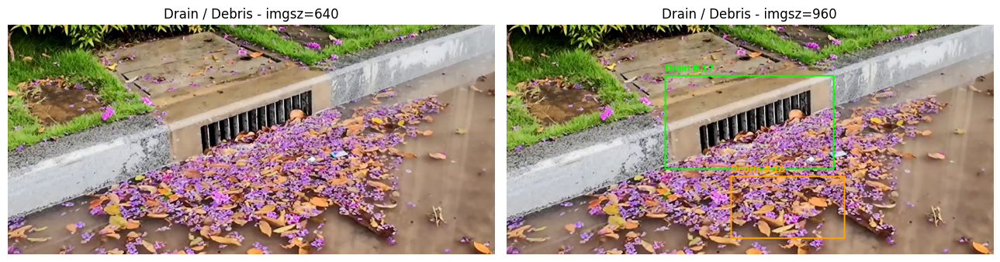

In [ ]:
## 이미지 크기 960으로 늘려서 재실험


# 배수구가 드러나는 시점의 프레임 검사
# second 값은 실제 영상에 맞게 수정


second = 2 # 확인할 영상 시점

cap = cv2.VideoCapture(input_path)
cap.set(cv2.CAP_PROP_POS_MSEC, second * 1000)
success, frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("해당 시점의 프레임을 읽지 못했습니다.")

fig, axes = plt.subplots(1, 2, figsize=(13, 7))

for ax, size in zip(axes, [640, 960]):
    result = model.predict(
        frame,
        conf=0.15,
        imgsz=size,
        device=device,
        verbose=False
    )[0]

    # Drain(0), Debris(2)만 표시
    annotated = result.plot(
        boxes=False,
        labels=False
    )

    for box in result.boxes:
        cls_id = int(box.cls.item())

        if cls_id not in [0, 2]:
            continue

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].cpu().tolist()
        )
        score = float(box.conf.item())
        name = model.names[cls_id]

        color = (0, 255, 0) if cls_id == 0 else (0, 165, 255)

        cv2.rectangle(
            annotated, (x1, y1), (x2, y2),
            color, 2
        )
        cv2.putText(
            annotated, f"{name} {score:.2f}",
            (x1, max(20, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7, color, 2
        )

    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Drain / Debris - imgsz={size}")
    ax.axis("off")

plt.tight_layout()
plt.show()



Debris 후보 수: 6
신뢰도: 0.0297
신뢰도: 0.0216
신뢰도: 0.0196
신뢰도: 0.019
신뢰도: 0.0123
신뢰도: 0.0107


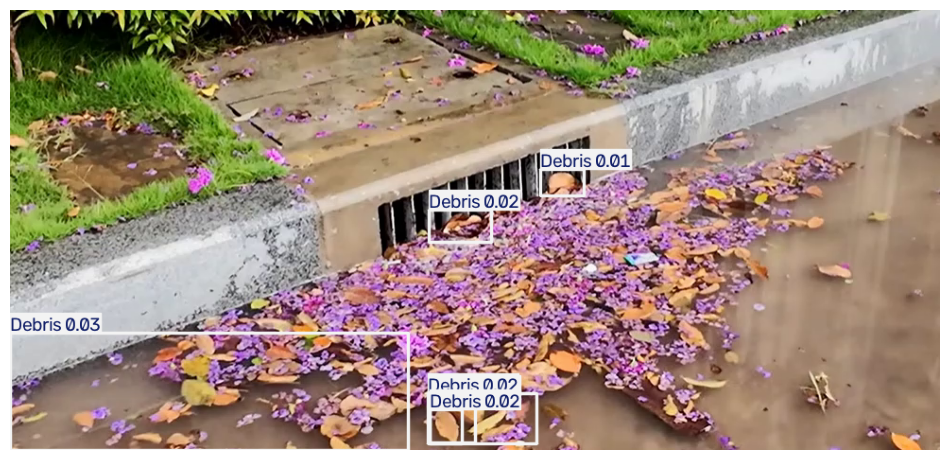

In [ ]:

# 현재 frame 변수에 검사할 영상 프레임이 들어 있다고 가정
# Debris(클래스 2)만 아주 낮은 신뢰도로 진단

result = model.predict(
    frame,
    classes=[2],
    conf=0.01,
    imgsz=640,
    device=device,
    verbose=False
)[0]

print("Debris 후보 수:", len(result.boxes))

for box in result.boxes:
    print("신뢰도:", round(float(box.conf.item()), 4))

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()



imgsz=640
Puddle: 0.498
Puddle: 0.177

imgsz=960
Puddle: 0.522
Debris: 0.318
Drain: 0.218
Debris: 0.184
Puddle: 0.155


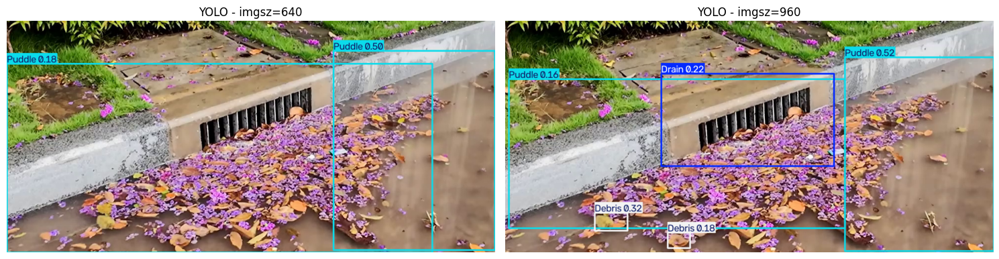

In [ ]:

import cv2
import matplotlib.pyplot as plt
import torch

video_path = str(base_dir / "videos/input.mp4")
device = 0 if torch.cuda.is_available() else "cpu"

cap = cv2.VideoCapture(video_path)
success, frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("영상 첫 프레임을 읽지 못했습니다.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, size in zip(axes, [640, 960]):
    result = model.predict(
        frame,
        conf=0.15,
        imgsz=size,
        device=device,
        verbose=False
    )[0]

    annotated = cv2.cvtColor(
        result.plot(), cv2.COLOR_BGR2RGB
    )

    ax.imshow(annotated)
    ax.set_title(f"YOLO - imgsz={size}")
    ax.axis("off")

    print(f"\nimgsz={size}")
    for box in result.boxes:
        name = model.names[int(box.cls.item())]
        score = float(box.conf.item())
        print(f"{name}: {score:.3f}")

plt.tight_layout()
plt.show()


일반 탐지 결과
Puddle: 0.522
Debris: 0.318
Drain: 0.218
Debris: 0.184
Puddle: 0.155


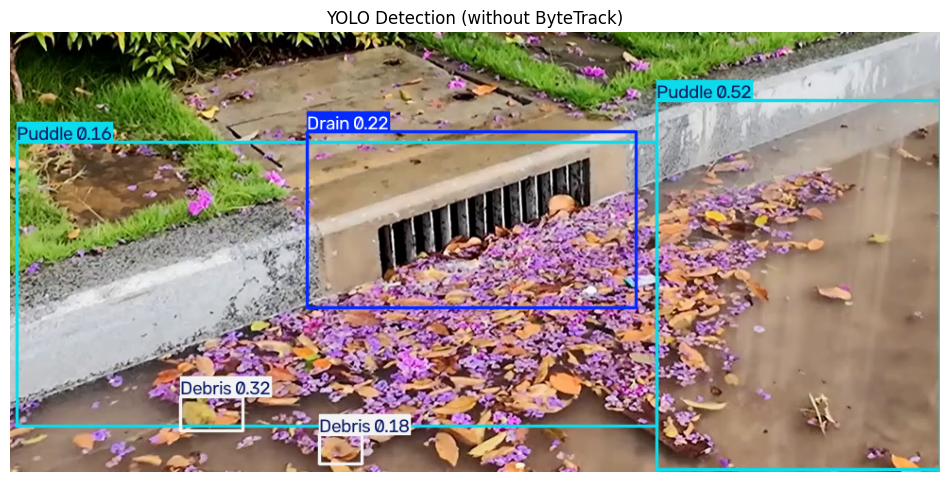

In [ ]:

import cv2
import matplotlib.pyplot as plt
import torch

device = 0 if torch.cuda.is_available() else "cpu"

cap = cv2.VideoCapture(input_path)
success, frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("프레임을 읽지 못했습니다.")

# 일반 탐지
result = model.predict(
    frame,
    conf=0.15,
    imgsz=960,
    device=device,
    verbose=False
)[0]

print("일반 탐지 결과")
for box in result.boxes:
    name = model.names[int(box.cls.item())]
    score = float(box.conf.item())
    print(f"{name}: {score:.3f}")

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
plt.title("YOLO Detection (without ByteTrack)")
plt.axis("off")
plt.show()
